# EDA — detecção de fraude
Reformulação do [projeto original](https://github.com/Mateusssssssssss/Projeto-Deteccao-De-Fraude).
Esta análise usa **somente o TRAIN cronológico, antes de qualquer reamostragem**.
Os cálculos ficam em `src/fraud_detection/eda.py`. Gere os artefatos com
`python -m fraud_detection.eda`. As figuras e tabelas abaixo são resultados persistidos reais.

## Problema, origem e dicionário
Uma linha representa uma transação. Queremos identificar fraude (**Class=1**) no momento
da autorização. FN deixa uma fraude passar; FP gera revisão ou bloqueio indevido. Sem
custos de negócio conhecidos, AP orienta a seleção e Precision/Recall/F1 descrevem o threshold.

Segundo o contexto fornecido com o projeto, a base contém transações europeias de dois
dias de setembro de 2013. O arquivo local é identificado por SHA-256 no manifesto do treino.
A procedência/licença da cópia deve ser verificada antes de redistribuir a base.

| Variável | Significado | Disponibilidade assumida |
|---|---|---|
| Time | Segundos desde a primeira transação | Exige marco temporal consistente |
| Amount | Valor da transação (moeda não informada no arquivo) | Autorização |
| V1–V28 | Componentes PCA anônimos, sem dicionário original | Autorização, hipótese não auditável |
| Class | 0 legítima; 1 fraude | Somente rótulo posterior, jamais feature |

O PCA fornecido não pode ser refeito sem os dados originais. Cópias exatas são removidas
deterministicamente, preservando o arquivo raw. Não há identificador de cliente para split
por grupo. O último quinto da duração é TEST; relações com target abaixo são só do TRAIN.

## Como interpretar as métricas

As tabelas abaixo têm rótulos descritivos. Percentuais são apenas uma forma de
exibir os valores: **0,000190 = 0,0190%**. Os CSVs conservam valores numéricos.

| Métrica | Pergunta que responde / denominador |
|---|---|
| Taxa de fraude na faixa | Entre as transações dessa faixa, quantas são fraude? = 100 × fraudes / transações da faixa. Não é erro do modelo. |
| Parcela das fraudes do TRAIN | Entre todas as fraudes do TRAIN, quantas estão nessa faixa? |
| Recall | Entre as fraudes reais, quantas o modelo detectou? = TP/(TP+FN). |
| Precision | Entre os alertas, quantos eram fraude real? = TP/(TP+FP). |
| F1 | Média harmônica de Precision e Recall, com peso simétrico. |
| F2 | Média harmônica que favorece Recall; objetivo das rodadas posteriores. |
| FP / FN | FP é legítima alertada; FN é fraude não detectada. TP/TN são acertos de fraude/legítima. |
| Taxa de falsos positivos | FP/(FP+TN): fração das legítimas que gerou alerta. |
| Parcela de alertas falsos | FP/(FP+TP) = 1−Precision. Tem denominador diferente da taxa de falsos positivos. |
| AP / curva PR | AP resume a curva Precision–Recall usando probabilidades; maior é melhor. Não equivale à área trapezoidal PR. |
| ROC-AUC | Resumo de ordenação fraude versus legítima; complementar à AP para classe rara. |
| Log Loss / Brier | Erros das probabilidades: menor é melhor. Não comprovam calibração. |
| Média e desvio de CV | Resumo entre folds temporais; desvio não é intervalo de confiança. |
| Correlação / importância | Correlação é associação com Class; importância de permutação é queda de AP na validação interna. Escalas distintas e sem causalidade. |

Se um segmento não tiver fraudes ou alertas, certas taxas ficam **Não definido**:
isso não significa taxa zero. Não some categorias de features distintas:
as mesmas transações reaparecem em cada feature.

Veja [o guia completo das métricas](../docs/metrics_guide.md), incluindo fórmulas,
unidades, outliers/IQR, assimetria, cardinalidade, diversidade OOF, threshold,
StandardScaler, SMOTE e limitações da validação.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    raise RuntimeError("Abra o notebook pela raiz do projeto ou pela pasta notebooks.")
METRICS = ROOT / "reports/metrics"
FIGURES = ROOT / "reports/figures"
EXPERIMENTS = ROOT / "reports/experiments"

def table(name, **kwargs):
    path = METRICS / name
    if not path.exists():
        raise FileNotFoundError(f"Artefato ausente: {path.name}. Execute os scripts conforme README.")
    return pd.read_csv(path, **kwargs)

def figure(name, width=1000):
    path = FIGURES / name
    if not path.exists():
        raise FileNotFoundError(f"Figura ausente: {path.name}. Execute os scripts conforme README.")
    display(Image(filename=str(path), width=width))

# Mantém os cálculos numéricos; traduz unidades e rótulos apenas ao exibir a tabela.
from fraud_detection.reporting import readable_table

def display_readable(frame):
    display(readable_table(frame))


## Dimensões, tipos, ausências e qualidade
Outliers por IQR são sinais para inspeção, não motivos automáticos de exclusão.

In [2]:
meta = json.loads((METRICS / "eda_metadata.json").read_text(encoding="utf-8"))
display(meta)
summary = table("eda_train_summary.csv", index_col=0)
display_readable(summary)
display(Markdown(f"O TRAIN possui **{meta['rows']:,}** linhas; há **{meta['missing_total']}** valores ausentes e **{meta['duplicates_train']}** cópias exatas restantes. O filtro removeu {meta['duplicates_removed']} duplicatas do arquivo completo antes do split."))

{'source': 'TRAIN temporal sem reamostragem',
 'rows': 210292,
 'columns': 31,
 'duplicates_train': 0,
 'missing_total': 0,
 'cutoff_time': 138233.6,
 'duplicates_removed': 1081}

Matplotlib is building the font cache; this may take a moment.


,Quantidade,Média,std,min,25%,50%,75%,max,Ausências,Valores distintos,Tipo de dado,Assimetria,"Valores fora de 1,5 IQR"
Time,"210.292,0000","74.066,8423","36.701,5756","0,0000","45.651,5000","69.590,0000","111.129,0000","138.230,0000",0,94.537,float64,"0,1752",0
V1,"210.292,0000","-0,0780","1,8956","-56,4075","-0,9502","-0,0561","1,2268","2,4549",0,204.968,float64,"-3,3309",5.268
V2,"210.292,0000","-0,0071","1,6238","-72,7157","-0,5897","0,0748","0,7783","22,0577",0,204.968,float64,"-4,6438",10.229
V3,"210.292,0000","0,2625","1,4560","-33,6810","-0,4371","0,4415","1,1915","9,3826",0,204.968,float64,"-2,7748",4.457
V4,"210.292,0000","0,0593","1,4019","-5,6832","-0,8077","0,0608","0,8621","16,8753",0,204.968,float64,"0,5405",6.069
V5,"210.292,0000","-0,0870","1,3602","-42,1479","-0,7665","-0,1477","0,4965","34,8017",0,204.968,float64,"-0,5393",9.991
V6,"210.292,0000","0,0395","1,3151","-26,1605","-0,7193","-0,2272","0,4379","22,5293",0,204.968,float64,"1,2502",17.027
V7,"210.292,0000","-0,0368","1,2063","-43,5572","-0,5706","-0,0002","0,5164","36,6773",0,204.968,float64,"-1,1892",6.816
V8,"210.292,0000","0,0108","1,1865","-73,2167","-0,1874","0,0381","0,3335","20,0072",0,204.968,float64,"-8,7492",17.908
V9,"210.292,0000","0,0047","1,1265","-13,4341","-0,6634","-0,0723","0,6190","15,5950",0,204.968,float64,"0,5784",5.726


O TRAIN possui **210,292** linhas; há **0** valores ausentes e **0** cópias exatas restantes. O filtro removeu 1081 duplicatas do arquivo completo antes do split.

## Classes e prevalência
A escala log permite ver a classe rara. A maioria não é reamostrada nesta análise.

,Quantidade,Proporção da classe (%)
Class,,
0,209.916,99.82%
1,376,0.18%


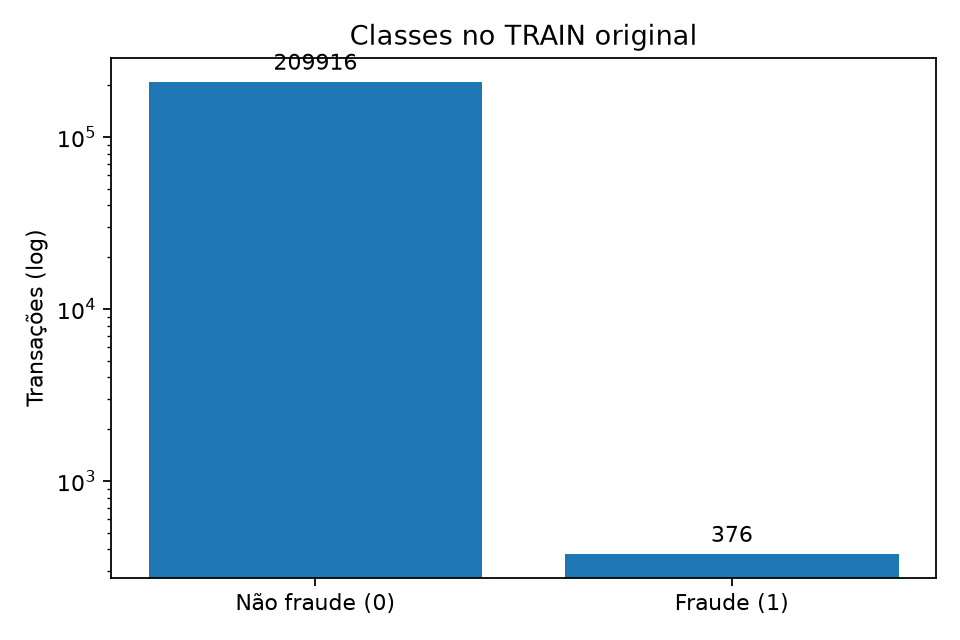

A prevalência de fraude no TRAIN é **0.179%**. Alta acurácia isolada pode refletir apenas a classe majoritária.

In [3]:
classes = table("eda_train_classes.csv", index_col=0)
display_readable(classes)
figure("eda_classes.png", 650)
display(Markdown(f"A prevalência de fraude no TRAIN é **{classes.loc[1, 'proportion']:.3%}**. Alta acurácia isolada pode refletir apenas a classe majoritária."))

## Distribuições, assimetria e valores extremos
V1–V28 já são componentes PCA. Não os tratamos como atributos originais interpretáveis. Valores extremos podem ser legítimos; não foram removidos.

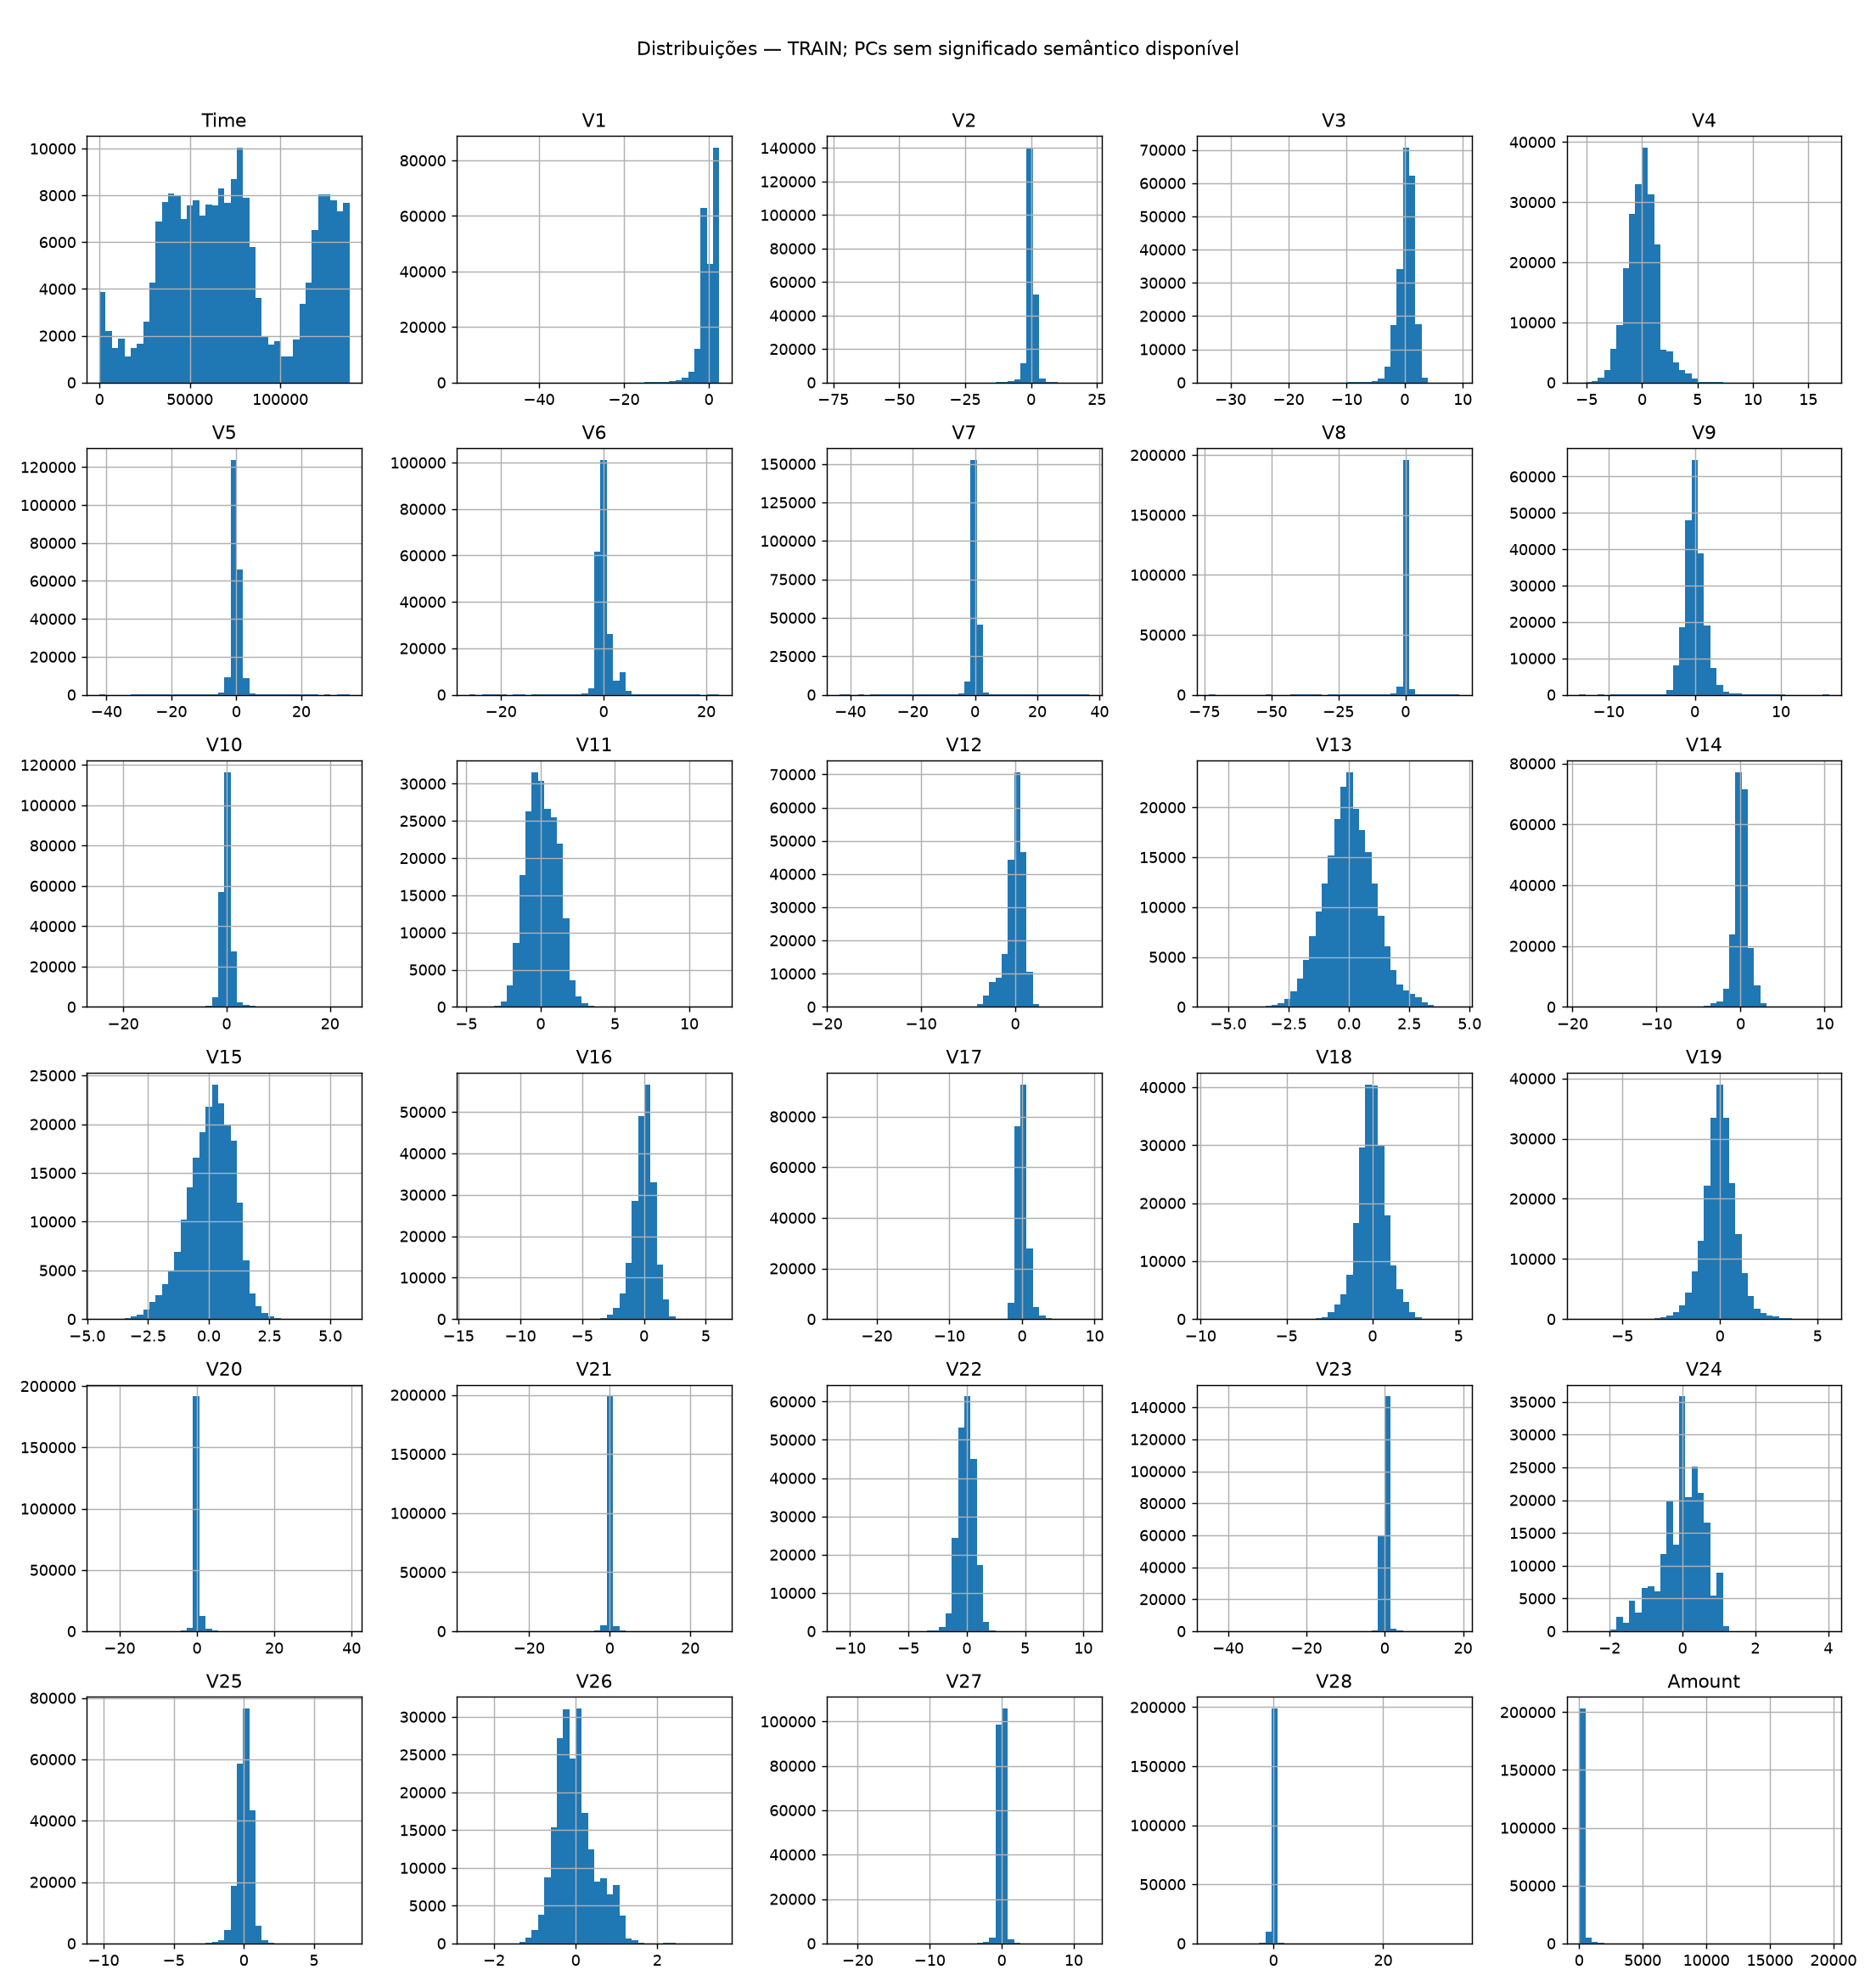

,skew,iqr_outliers,missing
V27,-2.363099,29258,0
V28,9.911729,24169,0
Amount,14.385629,23266,0
V20,-0.042757,20433,0
V8,-8.749199,17908,0
V6,1.250243,17027,0
V23,-5.355434,15255,0
V12,-2.219844,12883,0
V21,2.479002,11760,0
V14,-2.114096,11268,0


In [4]:
figure("eda_distributions.png", 1150)
display(summary[["skew", "iqr_outliers", "missing"]].sort_values("iqr_outliers", ascending=False).head(10))

## Valor, classes e tempo
O boxplot usa log(1+Amount) e oculta pontos extremos apenas no desenho. A curva mostra se a prevalência varia entre faixas temporais; cada faixa também tem contagem na tabela.

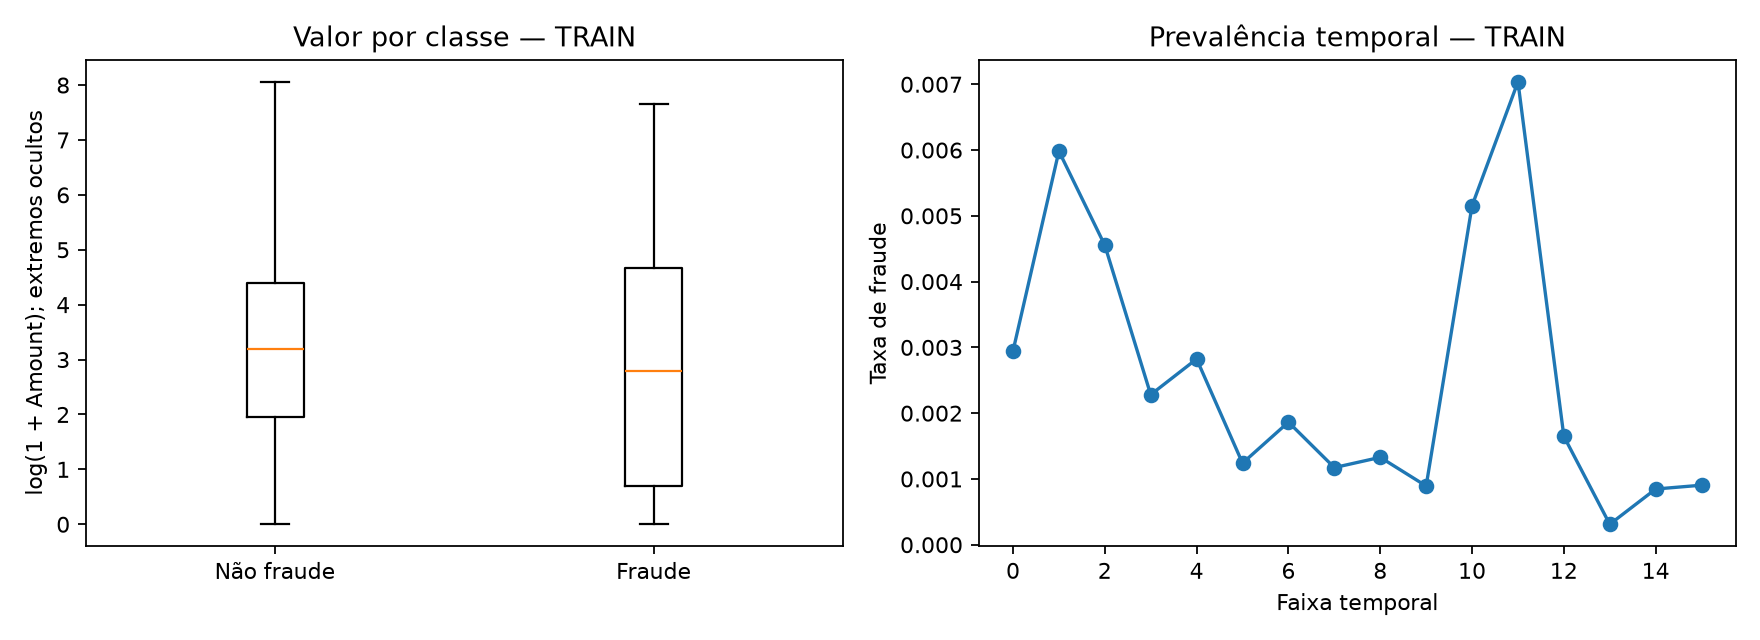

,Time,Transações,Taxa de fraude (%)
0,"(-138.23, 8639.375]",6.791,0.2945%
1,"(8639.375, 17278.75]",3.677,0.5983%
2,"(17278.75, 25918.125]",4.174,0.4552%
3,"(25918.125, 34557.5]",12.712,0.2281%
4,"(34557.5, 43196.875]",19.832,0.2824%
5,"(43196.875, 51836.25]",18.544,0.1240%
6,"(51836.25, 60475.625]",18.778,0.1864%
7,"(60475.625, 69115.0]",19.613,0.1173%
8,"(69115.0, 77754.375]",21.074,0.1329%
9,"(77754.375, 86393.75]",19.037,0.0893%


As taxas nas faixas de TRAIN variam de **0.031%** a **0.704%**. Esta variação é descritiva e pode envolver poucas fraudes por faixa.

In [5]:
figure("eda_amount_time.png")
time_rates = table("eda_time_prevalence.csv")
display_readable(time_rates)
display(Markdown(f"As taxas nas faixas de TRAIN variam de **{time_rates['mean'].min():.3%}** a **{time_rates['mean'].max():.3%}**. Esta variação é descritiva e pode envolver poucas fraudes por faixa."))

## Associações lineares e monotônicas
Pearson mede associação linear; Spearman, monotônica. Como Class é binária, Pearson aqui equivale à associação ponto-bisserial. Não há categóricas codificadas arbitrariamente.

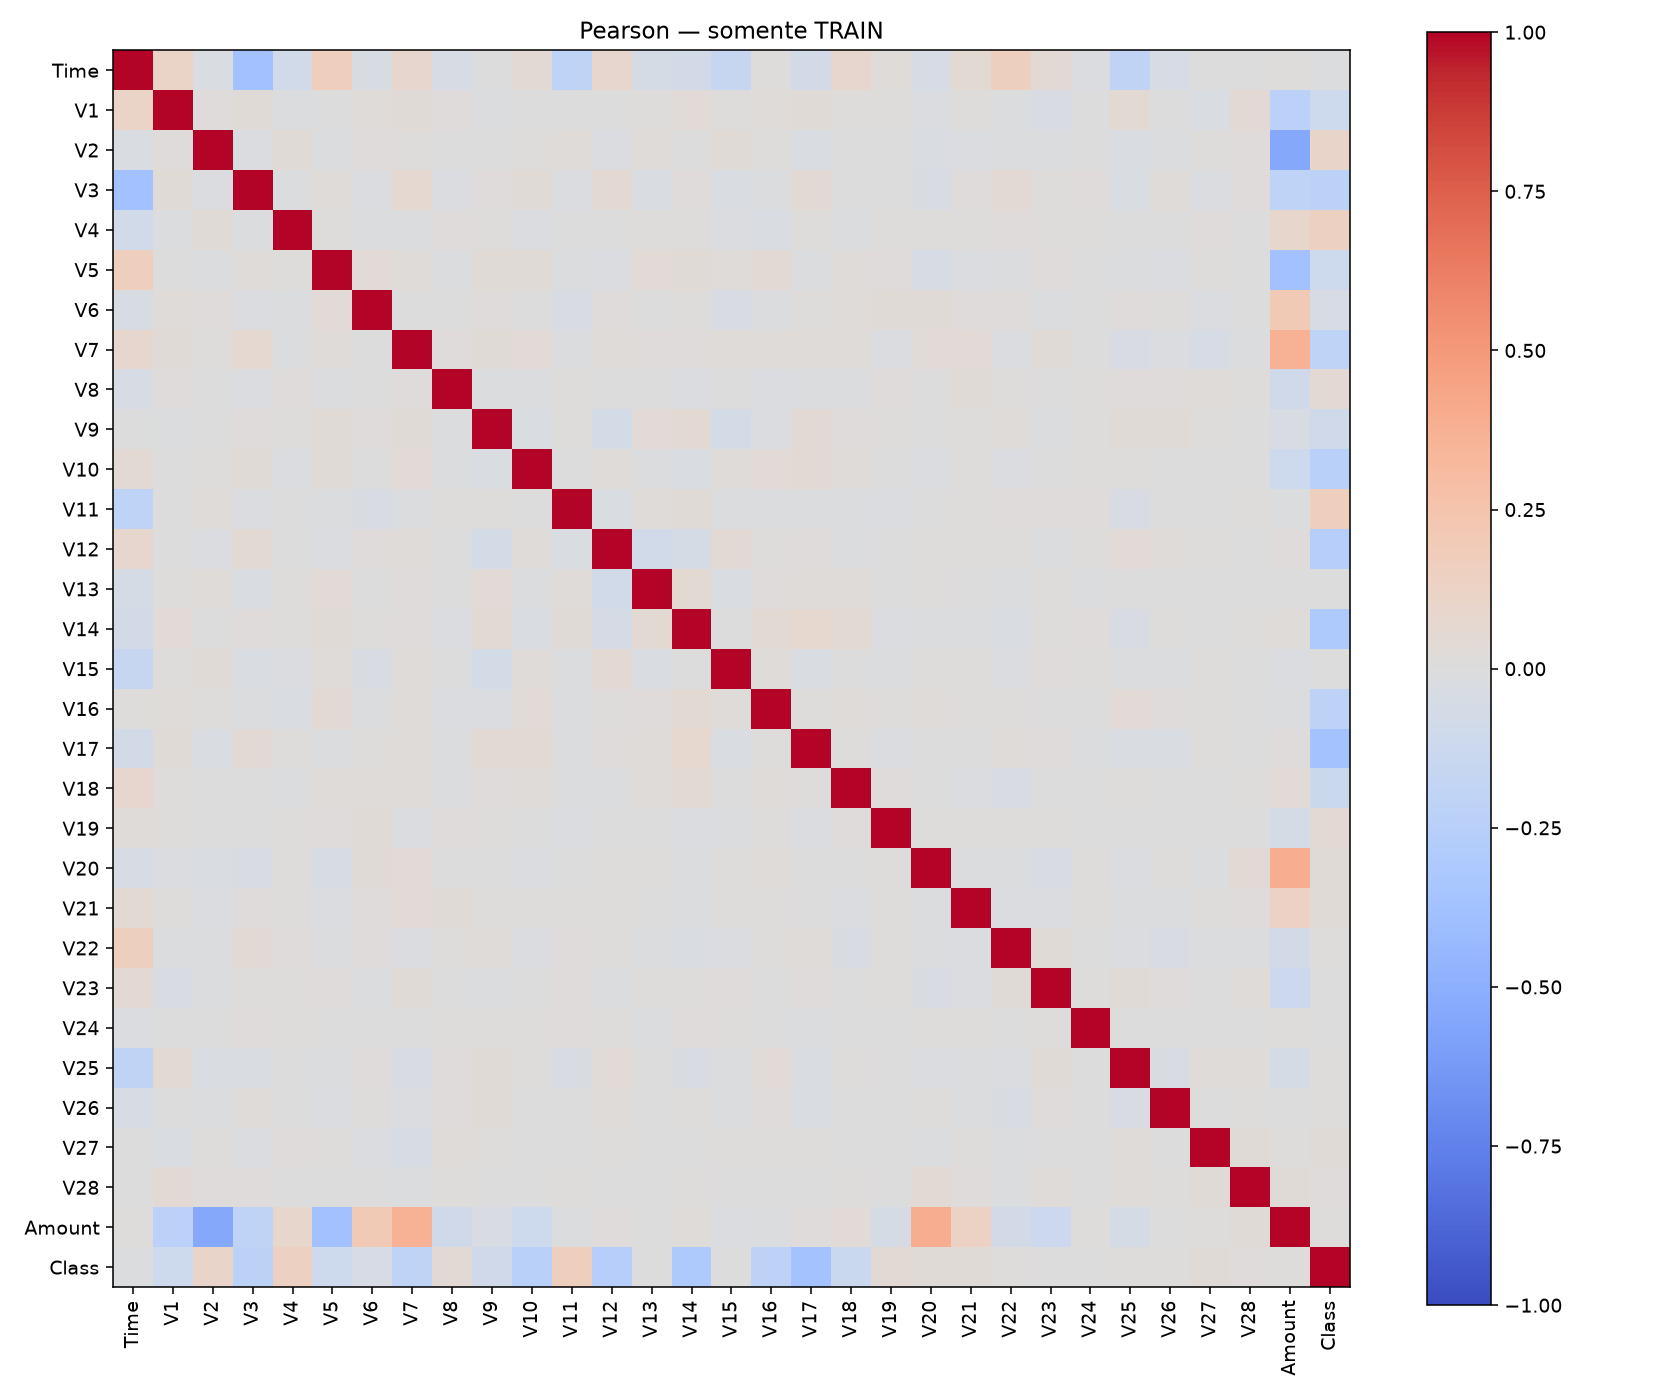

,Pearson com Class,Spearman com Class
V17,"-0,3597","-0,0453"
V14,"-0,3091","-0,0659"
V12,"-0,2624","-0,0644"
V10,"-0,2366","-0,0614"
V3,"-0,2197","-0,0610"
V16,"-0,2159","-0,0519"
V7,"-0,2106","-0,0497"
V11,"0,1608","0,0609"
V4,"0,1389","0,0640"
V18,"-0,1284","-0,0383"


Baixa correlação não exclui relações não lineares ou efeitos conjuntos. Nenhuma feature foi removida por esta tabela.

In [6]:
figure("eda_correlations.png")
associations = table("eda_associations.csv", index_col=0)
display_readable(associations.reindex(associations.pearson.abs().sort_values(ascending=False).index))
display(Markdown("Baixa correlação não exclui relações não lineares ou efeitos conjuntos. Nenhuma feature foi removida por esta tabela."))

## Formas não lineares, segmentos e interação
Quantis permitem examinar monotonicidade, curvaturas e extremos. Formato em U ou diferenças por segmento são hipóteses exploratórias; não provam efeito quadrático nem causalidade. As quatro PCs exibidas são escolhidas por associação no TRAIN para inspeção, sem seleção de features.

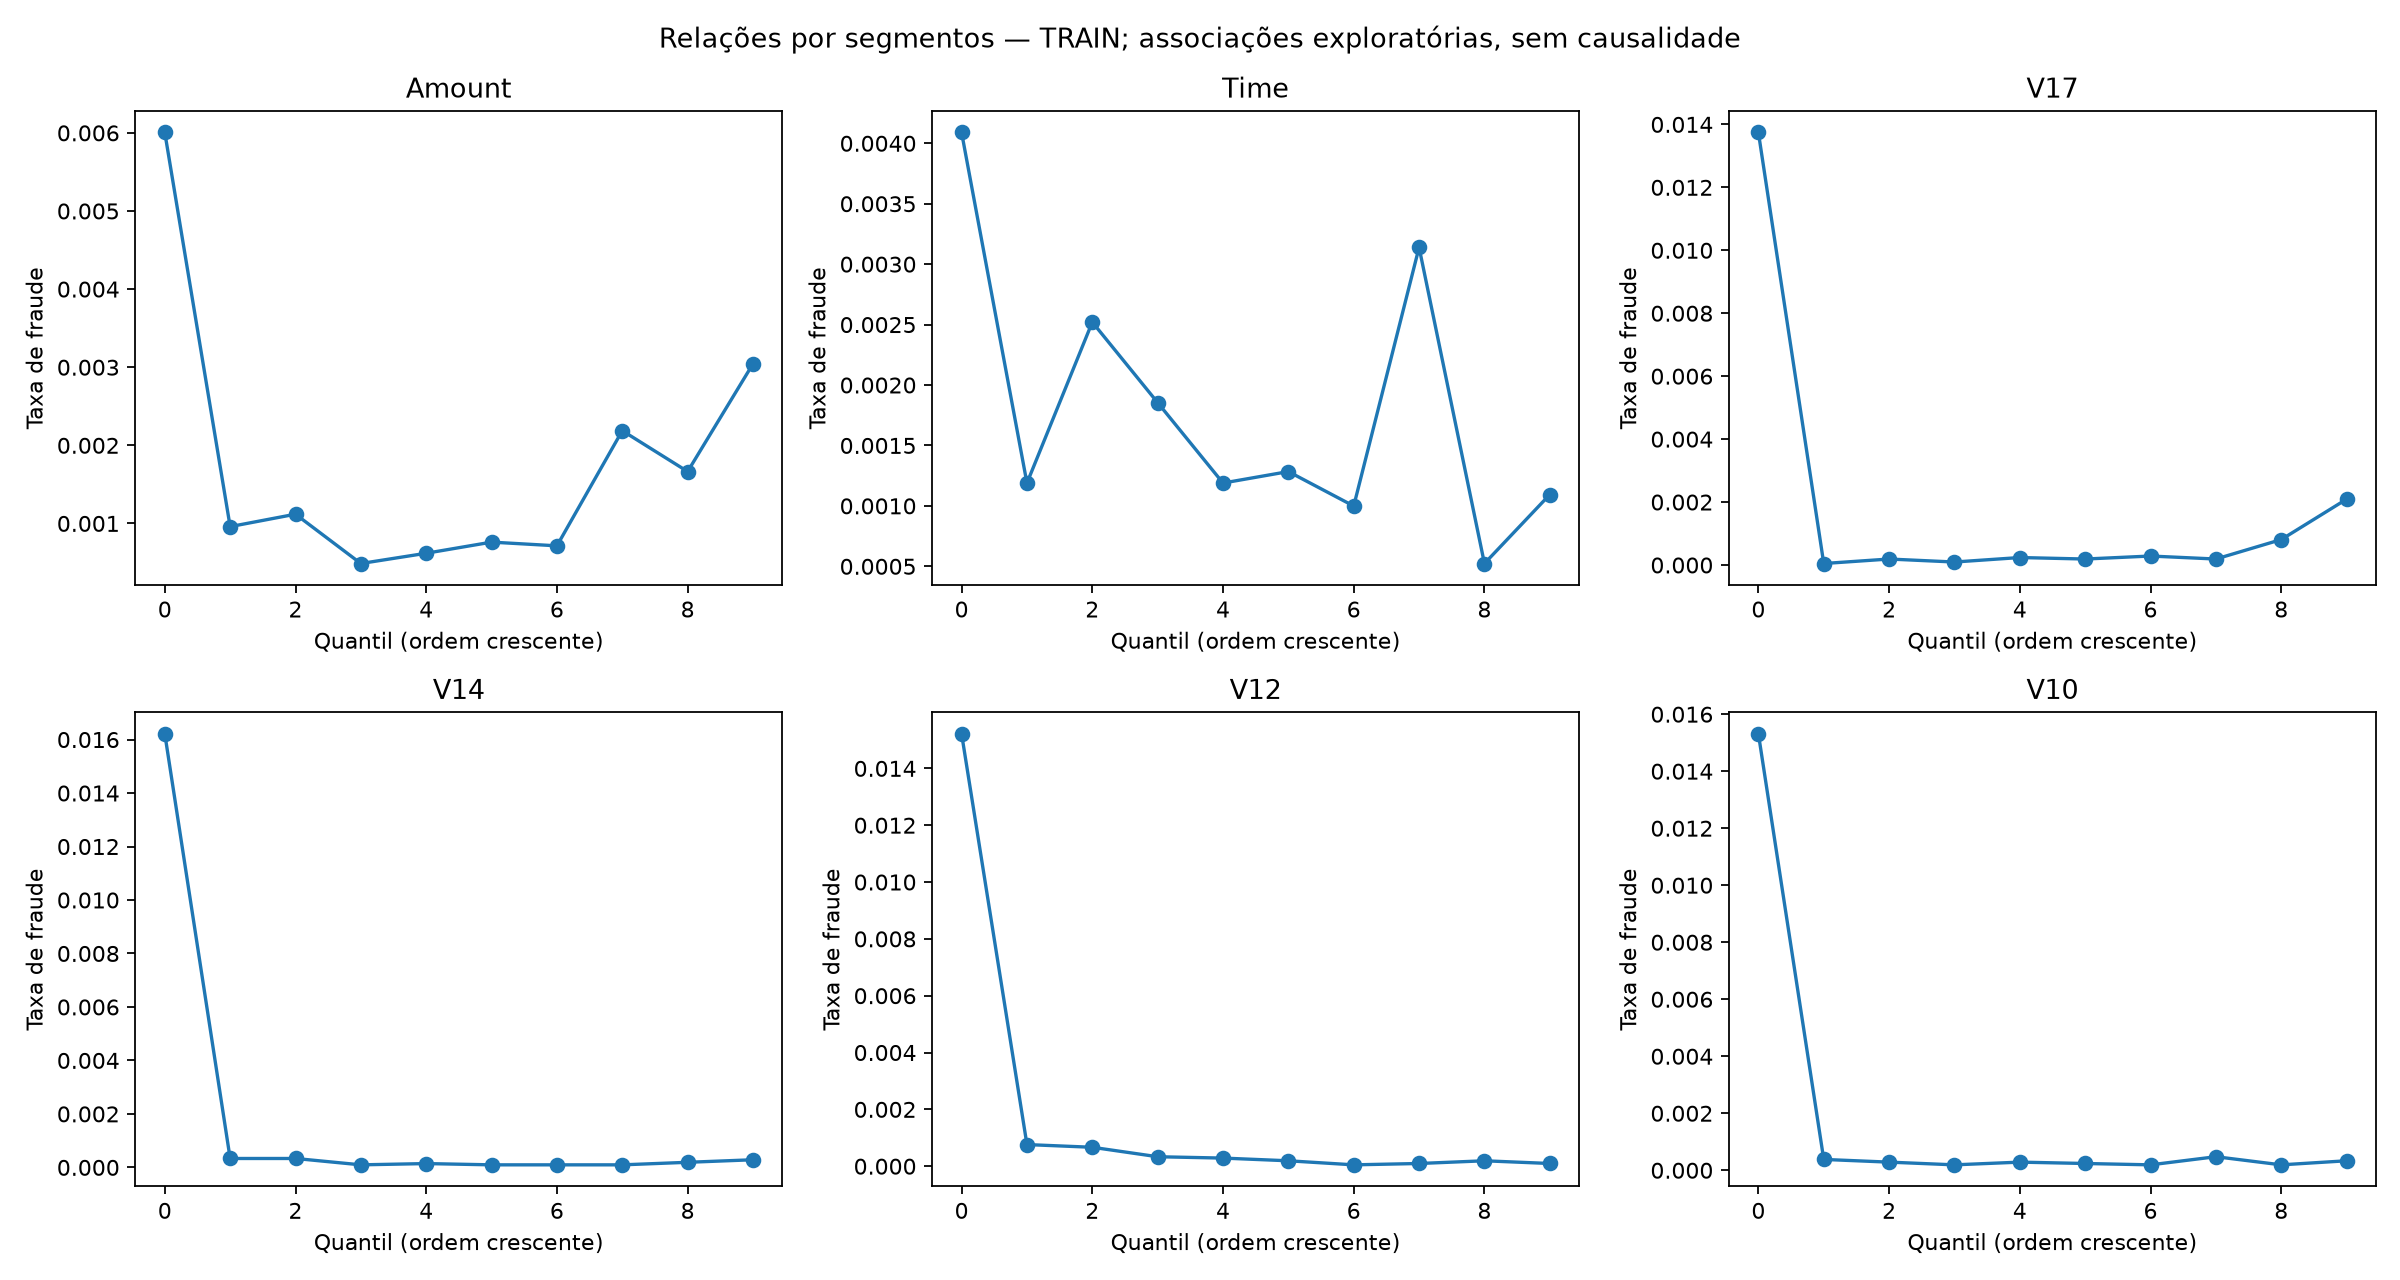

,Feature,Faixa de valores,Transações,Fraudes confirmadas,Transações legítimas,Fraude na faixa (%),Parcela das fraudes do TRAIN (%)
0,Time,"(-0.001, 31466.1]",21.030,86,20.944,0.4089%,22.87%
1,Time,"(31466.1, 41011.2]",21.029,25,21.004,0.1189%,6.65%
2,Time,"(41011.2, 50673.6]",21.029,53,20.976,0.2520%,14.10%
3,Time,"(50673.6, 60301.0]",21.032,39,20.993,0.1854%,10.37%
4,Time,"(60301.0, 69590.0]",21.027,25,21.002,0.1189%,6.65%
5,Time,"(69590.0, 78047.0]",21.030,27,21.003,0.1284%,7.18%
6,Time,"(78047.0, 88956.0]",21.028,21,21.007,0.0999%,5.59%
7,Time,"(88956.0, 119419.8]",21.028,66,20.962,0.3139%,17.55%
8,Time,"(119419.8, 128621.9]",21.029,11,21.018,0.0523%,2.93%
9,Time,"(128621.9, 138230.0]",21.030,23,21.007,0.1094%,6.12%


Cada taxa de fraude usa a contagem da própria faixa como denominador. Por exemplo, quatro fraudes em 21.029 transações correspondem a 0,0190%. A coluna de parcela das fraudes usa todas as fraudes do TRAIN como denominador.

,amount_band,component_band,Transações,Taxa de fraude (%)
0,alto,alto,54.645,0.0403%
1,alto,baixo,50.501,0.3049%
2,baixo,alto,50.501,0.1049%
3,baixo,baixo,54.645,0.2690%


A tabela de interação cruza Amount e a PC com maior associação absoluta, em faixas pela mediana do TRAIN. Diferenças nas taxas podem sugerir interação, mas precisam de validação e contagens suficientes; não geraram atributos novos nesta rodada.

In [7]:
figure("eda_nonlinear.png")
feature_bins = table("eda_feature_bins.csv")
display_readable(feature_bins[
    ["feature", "bin", "size", "fraud_count", "legitimate_count",
     "fraud_rate_pct", "share_of_train_frauds_pct"]
])
display(Markdown(
    "Cada taxa de fraude usa a contagem da própria faixa como denominador. "
    "Por exemplo, quatro fraudes em 21.029 transações correspondem a 0,0190%. "
    "A coluna de parcela das fraudes usa todas as fraudes do TRAIN como denominador."
))
display_readable(table("eda_interaction.csv"))
display(Markdown("A tabela de interação cruza Amount e a PC com maior associação absoluta, em faixas pela mediana do TRAIN. Diferenças nas taxas podem sugerir interação, mas precisam de validação e contagens suficientes; não geraram atributos novos nesta rodada."))

## Correlação com a target × importância das features
Os dois painéis alinham **todas as 30 features**, na mesma ordem, pela importância
de permutação do XGBoost selecionado.

- **Esquerda:** correlação de Pearson com Class, calculada no TRAIN original.
  Para esse target binário, é associação ponto-bisserial. O sinal mostra a direção
  da associação linear; as cores distinguem sinais positivo e negativo.
- **Direita:** queda de Average Precision ao permutar cada feature na última
  janela de validação dentro do TRAIN, com o modelo ajustado apenas no passado.
  Barras de erro representam desvio entre três permutações.

Esta é uma seção de diagnóstico **após modelagem**, incorporada à EDA para consulta.
A validação já participou da seleção do modelo; importância é descritiva e
condicionada a essa seleção. Não se usa TEST nem se eliminam features a partir
desse gráfico. **As escalas são distintas; correlação e importância não implicam
causalidade.** Features correlacionadas podem compartilhar importância, e baixa
correlação linear não exclui relações não lineares.

,Feature,Pearson com Class,Spearman com Class,Queda de AP por permutação,Desvio da permutação,Importância interna da árvore
14,V14,"-0,3091","-0,0659","0,2438","0,0189","0,2099"
4,V4,"0,1389","0,0640","0,1041","0,0175","0,0267"
10,V10,"-0,2366","-0,0614","0,0659","0,0021","0,3075"
7,V7,"-0,2106","-0,0497","0,0277","0,0054","0,0098"
12,V12,"-0,2624","-0,0644","0,0217","0,0161","0,0376"
16,V16,"-0,2159","-0,0519","0,0157","0,0023","0,0663"
17,V17,"-0,3597","-0,0453","0,0148","0,0032","0,1286"
8,V8,"0,0406","0,0240","0,0109","0,0050","0,0095"
28,V28,"0,0082","0,0197","0,0105","0,0038","0,0086"
3,V3,"-0,2197","-0,0610","0,0085","0,0034","0,0184"


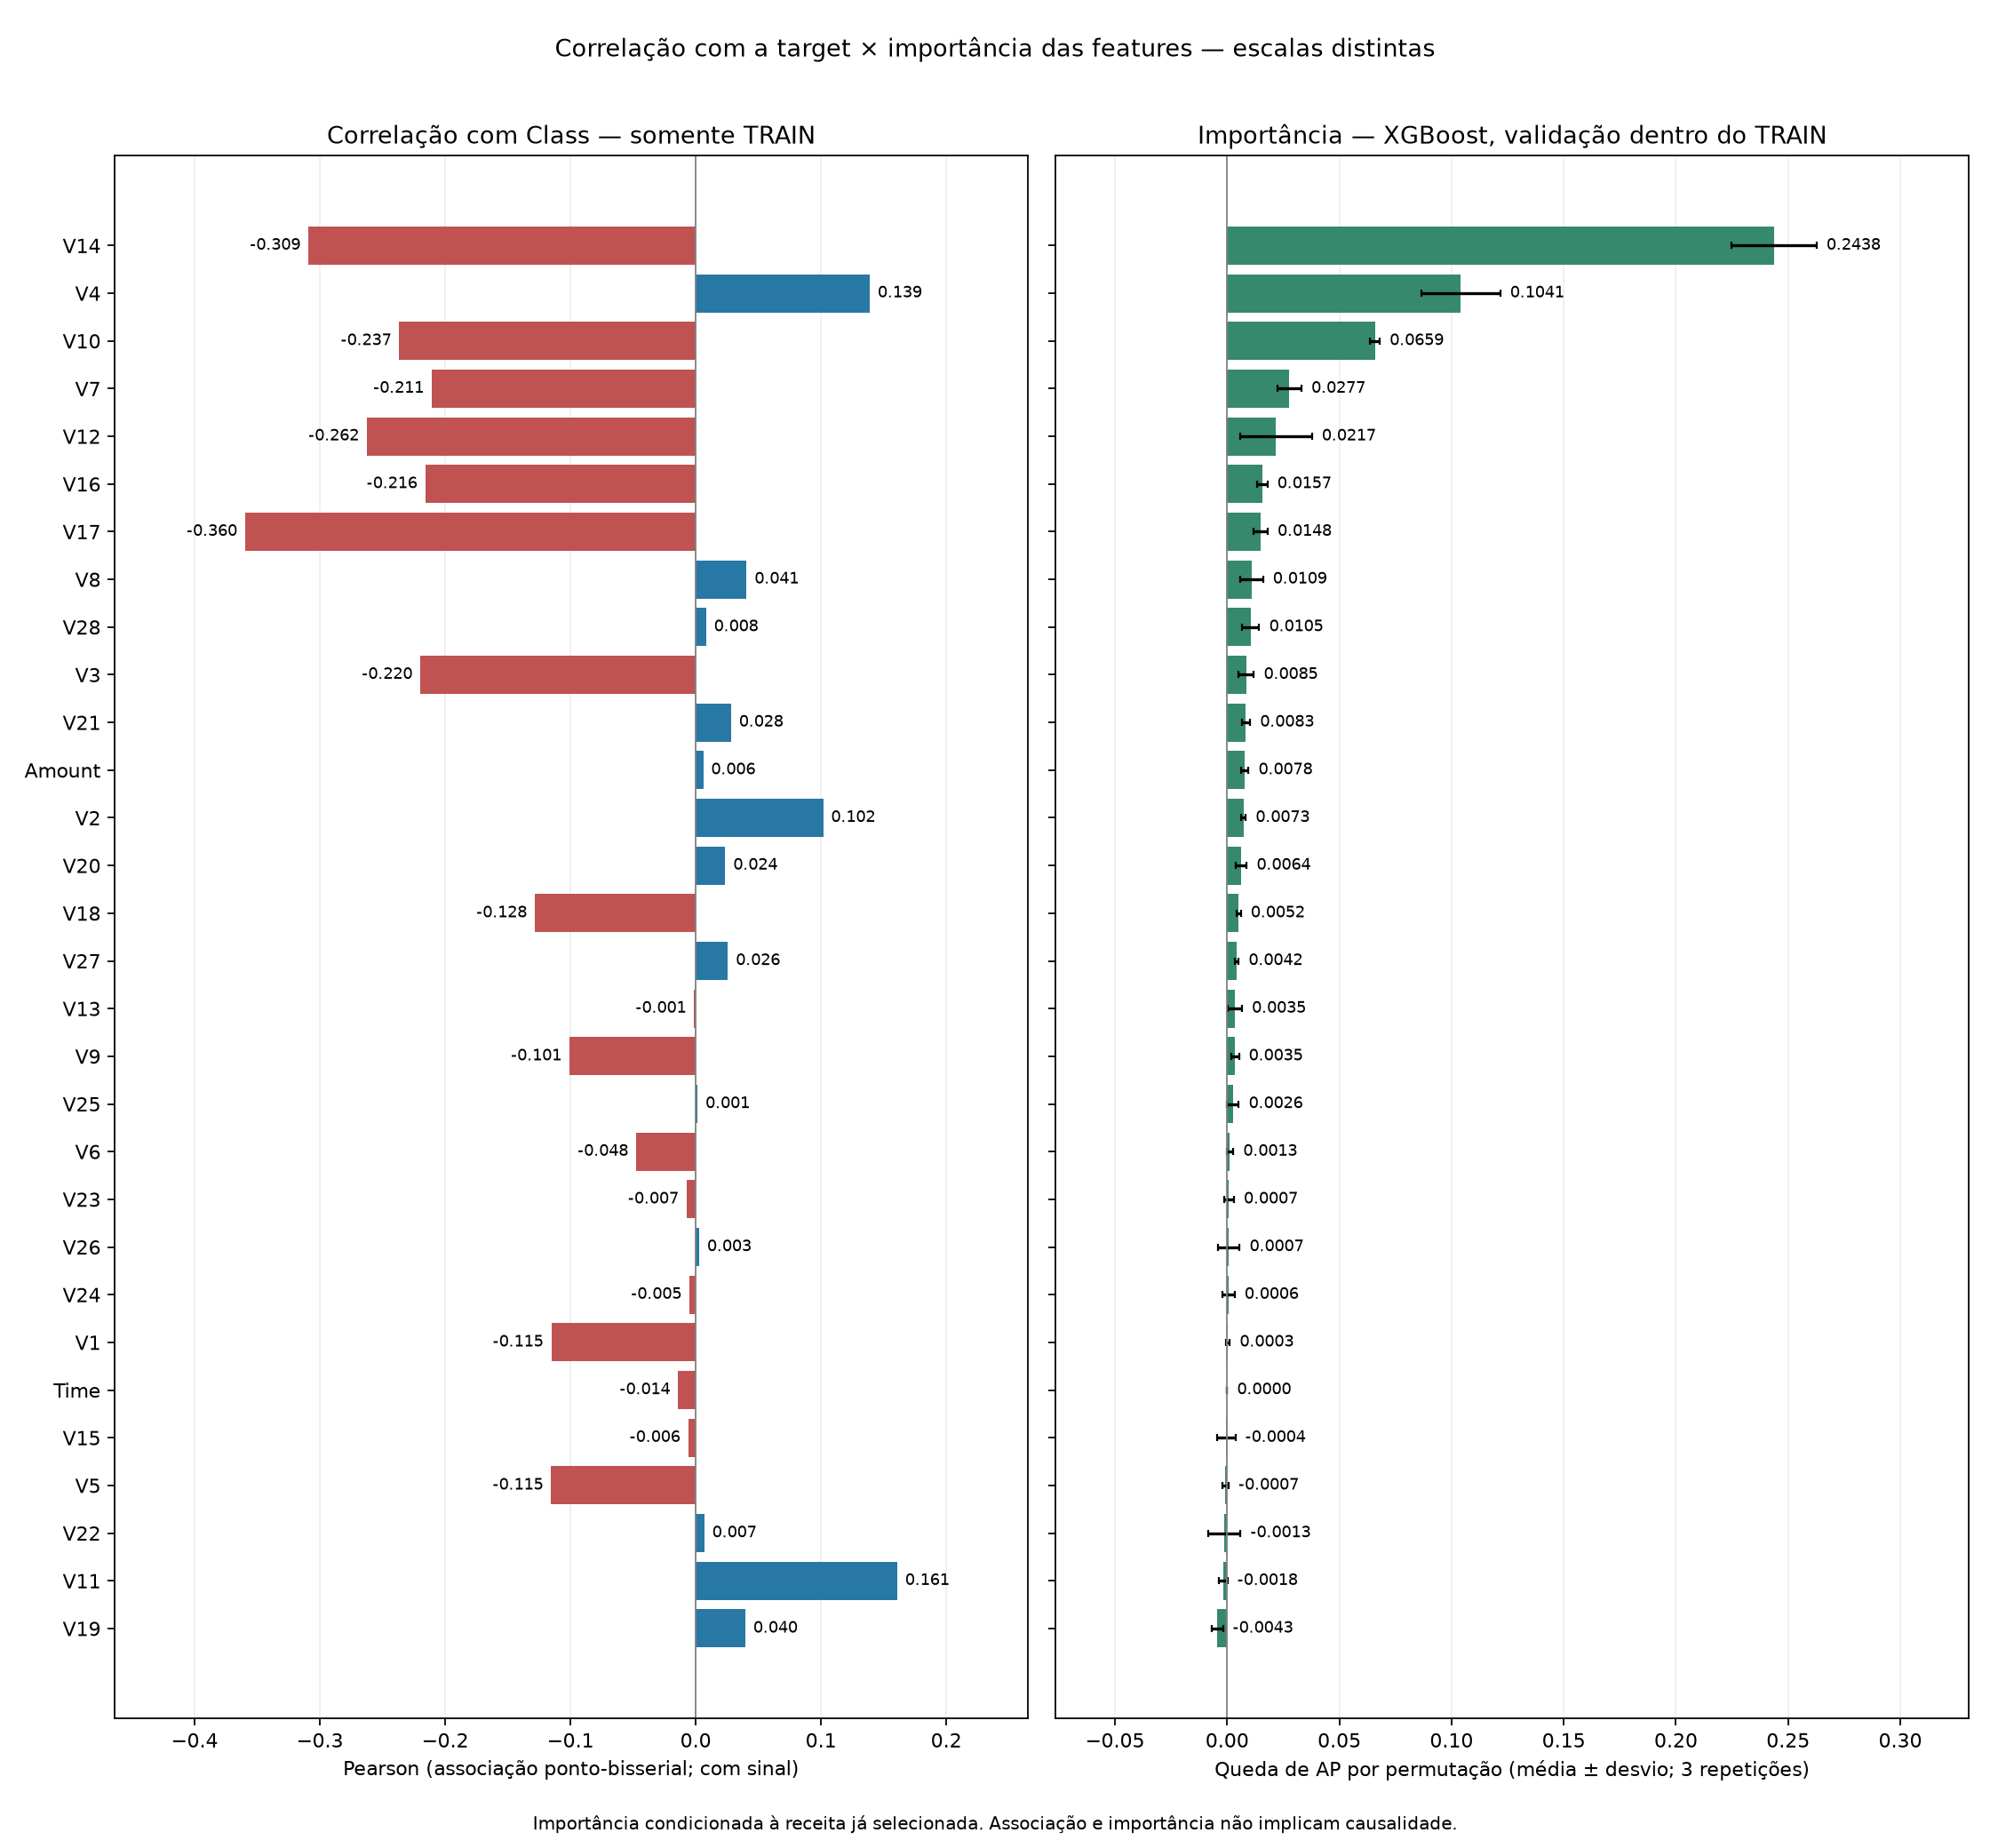

A importância de árvore também está na tabela, mas pode ter vieses e dividir crédito entre features correlacionadas. O painel usa permutação em validação como diagnóstico principal.

In [8]:
importance_path = METRICS / "association_importance.csv"
comparison_figure = FIGURES / "eda_target_correlation_importance.png"
if importance_path.exists() and comparison_figure.exists():
    feature_comparison = table("association_importance.csv").sort_values(
        "permutation_ap", ascending=False
    )
    display_readable(feature_comparison[
        ["feature", "pearson", "spearman", "permutation_ap",
         "permutation_std", "tree_importance"]
    ])
    figure("eda_target_correlation_importance.png", 1150)
    display(Markdown(
        "A importância de árvore também está na tabela, mas pode ter vieses e "
        "dividir crédito entre features correlacionadas. "
        "O painel usa permutação em validação como diagnóstico principal."
    ))
else:
    display(Markdown(
        "Diagnóstico ainda indisponível. Execute primeiro "
        "**python -m fraud_detection.train** (apenas se os artefatos de treino "
        "ainda não existirem), depois **python -m fraud_detection.eda**. "
        "Não é necessário repetir treino para abrir este notebook."
    ))

## Hipóteses e próximos passos
Compare receitas com e sem reamostragem em CV temporal; o efeito do balanceamento não se
deduz da EDA. Observe a estabilidade por janela e a relação entre Precision e Recall.
Correlação versus importância do modelo aparece acima e no notebook **03_model_metrics.ipynb**.
Não há análise feature–target do TEST neste notebook. A base curta, o PCA pré-computado
e a falta de grupos limitam a generalização; ver `docs/methodology.md`.